<a href="https://colab.research.google.com/github/sreya2702/C-22-myOwnLibrary/blob/master/NASA_Exoplanet_Discovery_Analytics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

import plotly.express as px
import plotly.graph_objects as go

import requests
from io import StringIO

import sqlite3

from scipy import stats

import warnings
warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
BASE_URL = "https://exoplanetarchive.ipac.caltech.edu/TAP/sync"

In [ ]:
columns = [
    # Identification
    "pl_name",
    "hostname",
    "gaia_dr3_id",

    # Discovery information
    "discoverymethod",
    "disc_year",
    "disc_facility",
    "disc_locale",
    "disc_telescope",

    # System information
    "sy_pnum",
    "sy_snum",
    "sy_dist",

    # Planet properties
    "pl_orbper",
    "pl_orbsmax",
    "pl_rade",
    "pl_bmasse",
    "pl_eqt",
    "pl_orbeccen",
    "pl_insol",

    # Host-star properties
    "st_teff",
    "st_rad",
    "st_mass",
    "st_met"
]

print("Number of selected columns:", len(columns))

Number of selected columns: 22


In [ ]:
query = f"""
SELECT {','.join(columns)}
FROM pscomppars
"""

print(query)


SELECT pl_name,hostname,gaia_dr3_id,discoverymethod,disc_year,disc_facility,disc_locale,disc_telescope,sy_pnum,sy_snum,sy_dist,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,pl_orbeccen,pl_insol,st_teff,st_rad,st_mass,st_met
FROM pscomppars



In [ ]:
params = {
    "query": query,
    "format": "csv"
}

response = requests.get(
    BASE_URL,
    params=params,
    timeout=60
)

response.raise_for_status()

df = pd.read_csv(StringIO(response.text))

print("NASA data downloaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

NASA data downloaded successfully!
Rows: 6336
Columns: 22


In [ ]:
df.head()

,pl_name,hostname,gaia_dr3_id,discoverymethod,disc_year,disc_facility,disc_locale,disc_telescope,sy_pnum,sy_snum,sy_dist,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,pl_orbeccen,pl_insol,st_teff,st_rad,st_mass,st_met
0,HD 80653 b,HD 80653,Gaia DR3 606477252238780160,Transit,2020,K2,Space,0.95 m Kepler Telescope,2,1,109.860,0.719579,0.01657,1.621000,5.610000,2438.00,0.0000,6130.0000,5959.0,1.199,1.150,0.255
1,K2-312 c,HD 80653,Gaia DR3 606477252238780160,Radial Velocity,2023,Roque de los Muchachos Observatory,Ground,3.58 m Telescopio Nazionale Galileo,2,1,109.860,871.320000,1.88200,12.800000,1681.312273,229.00,0.8435,0.4596,5959.0,1.199,1.150,0.255
2,XO-2 S d,XO-2 S,Gaia DR3 934346740559239296,Radial Velocity,2024,Multiple Observatories,Ground,Multiple Telescopes,4,2,151.398,4696.000000,5.46000,13.000000,1179.143390,110.98,0.0910,0.0253,5325.0,1.020,0.980,0.320
3,Kepler-1808 b,Kepler-1808,Gaia DR3 2100414933904708608,Transit,2021,Kepler,Space,0.95 m Kepler Telescope,1,1,1022.010,23.340401,0.14670,3.025113,9.400000,601.00,0.0000,30.9400,5530.0,0.892,0.773,-0.340
4,Kepler-418 b,Kepler-418,Gaia DR3 2052117923590073600,Transit,2014,Kepler,Space,0.95 m Kepler Telescope,2,1,1002.530,86.678560,0.39249,13.450000,349.611248,434.00,0.2000,8.8770,5820.0,1.090,0.980,-0.050


In [ ]:
df.tail()

,pl_name,hostname,gaia_dr3_id,discoverymethod,disc_year,disc_facility,disc_locale,disc_telescope,sy_pnum,sy_snum,sy_dist,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,pl_orbeccen,pl_insol,st_teff,st_rad,st_mass,st_met
6331,TOI-2384 b,TOI-2384,Gaia DR3 4699702272124241152,Transit,2024,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,1,2,191.5100,2.135703,0.02793,11.489205,624.850648,889.7,0.000,104.3000,3943.0,0.6113,0.635,0.332
6332,TOI-5292 A b,TOI-5292 A,Gaia DR3 2610422023759160576,Transit,2026,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,1,2,337.0950,2.021910,0.02790,12.643730,412.859101,809.0,0.034,102.0000,3919.0,0.6110,0.596,0.330
6333,TIC 46432937 b,TIC 46432937,Gaia DR3 2984391358868786816,Transit,2024,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,1,2,90.5369,1.440445,0.02065,13.316269,1017.050902,872.0,0.009,115.1312,3572.0,0.5299,0.563,0.323
6334,HD 60779 b,HD 60779,Gaia DR3 3060787930730737920,Transit,2026,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,2,1,35.4445,29.986175,0.19220,3.246000,14.190000,650.0,0.031,42.3921,6081.0,1.1290,1.050,-0.120
6335,HD 60779 c,HD 60779,Gaia DR3 3060787930730737920,Radial Velocity,2026,Roque de los Muchachos Observatory,Ground,3.58 m Telescopio Nazionale Galileo,2,1,35.4445,104.790000,NaN,5.790000,28.300000,NaN,0.041,NaN,6081.0,1.1290,1.050,-0.120


In [ ]:
df.sample(10, random_state=42)

,pl_name,hostname,gaia_dr3_id,discoverymethod,disc_year,disc_facility,disc_locale,disc_telescope,sy_pnum,sy_snum,sy_dist,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,pl_orbeccen,pl_insol,st_teff,st_rad,st_mass,st_met
1357,TOI-512 b,TOI-512,Gaia DR3 5574111674620962688,Transit,2025,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,1,1,67.3975,7.188860,NaN,1.540000,3.570000,1009.00,0.020,127.0000,5277.00,0.890000,0.740000,-0.110
2080,HD 18143 b,HD 18143,Gaia DR3 116037204451525376,Radial Velocity,2022,Multiple Observatories,Ground,Multiple Telescopes,2,1,22.5243,10.285100,0.08800,3.280000,10.806166,769.92,0.224,61.8730,5078.00,0.870000,0.850000,0.280
2718,TOI-5486 b,TOI-5486,Gaia DR3 3704041819694603904,Transit,2026,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,1,1,89.6811,2.024701,NaN,3.968249,14.900000,752.00,NaN,53.3297,3750.17,0.553216,0.548138,NaN
812,TOI-5624 d,TOI-5624,Gaia DR3 1546352569189373952,Transit,2026,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,5,1,101.9130,13.731468,0.10670,3.584000,4.900000,712.60,0.000,157.0550,5327.00,0.820000,0.858000,-0.023
4886,WISPIT 1 c,WISPIT 1,Gaia DR3 5517037434775143808,Imaging,2025,Paranal Observatory,Ground,8.2 m ESO VLT UT3 Melipal Telescope,2,2,230.0070,NaN,840.00000,12.800000,1684.490557,8.21,NaN,0.0000,4670.00,1.116100,0.720000,NaN
4890,Kepler-846 b,Kepler-846,Gaia DR3 2131294885469721984,Transit,2016,Kepler,Space,0.95 m Kepler Telescope,1,1,1127.1200,19.807922,0.13990,2.480000,6.710000,624.00,0.000,35.2760,5579.00,0.910000,0.940000,0.000
4714,TOI-782 b,TOI-782,Gaia DR3 3518374197418907648,Transit,2024,Transiting Exoplanet Survey Satellite (TESS),Space,0.1 m TESS Telescope,1,1,52.5122,8.024002,0.05780,2.734000,19.100000,435.00,0.190,5.9100,3370.00,0.413000,0.397000,0.340
1782,K2-385 b,K2-385,Gaia DR3 2552976943549668352,Transit,2022,K2,Space,0.95 m Kepler Telescope,1,1,420.8190,2.380867,NaN,1.539000,2.980000,NaN,NaN,NaN,4844.00,0.761000,0.927000,-0.224
2445,K2-46 b,K2-46,Gaia DR3 3794162976731206272,Transit,2016,K2,Space,0.95 m Kepler Telescope,1,1,449.2370,19.154100,0.13821,2.050000,4.860000,889.00,NaN,119.0000,6256.00,1.290000,0.960000,-0.320
3574,K2-187 e,K2-187,Gaia DR3 689268759823937280,Transit,2018,K2,Space,0.95 m Kepler Telescope,4,1,330.9160,13.606629,0.11060,1.900000,4.270000,698.00,NaN,52.0501,5438.00,0.830000,0.966999,0.000


In [ ]:
print("Dataset shape:", df.shape)

print("\nNumber of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (6336, 22)

Number of rows: 6336
Number of columns: 22


In [ ]:
df.columns.tolist()

['pl_name',
 'hostname',
 'gaia_dr3_id',
 'discoverymethod',
 'disc_year',
 'disc_facility',
 'disc_locale',
 'disc_telescope',
 'sy_pnum',
 'sy_snum',
 'sy_dist',
 'pl_orbper',
 'pl_orbsmax',
 'pl_rade',
 'pl_bmasse',
 'pl_eqt',
 'pl_orbeccen',
 'pl_insol',
 'st_teff',
 'st_rad',
 'st_mass',
 'st_met']

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6336 entries, 0 to 6335
Data columns (total 22 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   pl_name          6336 non-null   object 
 1   hostname         6336 non-null   object 
 2   gaia_dr3_id      5955 non-null   object 
 3   discoverymethod  6336 non-null   object 
 4   disc_year        6336 non-null   int64  
 5   disc_facility    6336 non-null   object 
 6   disc_locale      6336 non-null   object 
 7   disc_telescope   6336 non-null   object 
 8   sy_pnum          6336 non-null   int64  
 9   sy_snum          6336 non-null   int64  
 10  sy_dist          6309 non-null   float64
 11  pl_orbper        5992 non-null   float64
 12  pl_orbsmax       5908 non-null   float64
 13  pl_rade          6286 non-null   float64
 14  pl_bmasse        6305 non-null   float64
 15  pl_eqt           5810 non-null   float64
 16  pl_orbeccen      5283 non-null   float64
 17  pl_insol      

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
disc_year,6336.0,2017.249369,5.119349e+00,1992.000000,2014.000000,2016.000000,2021.000000,2.026000e+03
sy_pnum,6336.0,1.759785,1.150985e+00,1.000000,1.000000,1.000000,2.000000,8.000000e+00
sy_snum,6336.0,1.101641,3.395858e-01,1.000000,1.000000,1.000000,1.000000,4.000000e+00
sy_dist,6309.0,704.333640,1.215827e+03,1.301190,101.251000,360.313000,823.242000,8.500000e+03
pl_orbper,5992.0,71444.635933,5.195691e+06,0.090706,4.308908,10.745507,38.562753,4.020000e+08
pl_orbsmax,5908.0,15.545361,3.468536e+02,0.004400,0.052300,0.102750,0.311250,1.900000e+04
pl_rade,6286.0,5.851832,5.422517e+00,0.309800,1.850000,2.860000,11.915990,8.720587e+01
pl_bmasse,6305.0,404.433376,1.139778e+03,0.020000,4.310000,9.320000,189.425731,9.534852e+03
pl_eqt,5810.0,834.896141,4.966198e+02,1.480000,485.895000,755.625000,1092.750000,7.777780e+03
pl_orbeccen,5283.0,0.079915,1.531730e-01,0.000000,0.000000,0.000000,0.092000,9.500000e-01


In [ ]:
raw_df = df.copy()

print("Raw dataset preserved.")

Raw dataset preserved.


In [ ]:
print(raw_df.shape)

(6336, 22)


In [ ]:
duplicate_planets = df.duplicated(subset="pl_name").sum()

print("Duplicate planet names:", duplicate_planets)

Duplicate planet names: 0


In [ ]:
df[df.duplicated(subset="pl_name", keep=False)]

,pl_name,hostname,gaia_dr3_id,discoverymethod,disc_year,disc_facility,disc_locale,disc_telescope,sy_pnum,sy_snum,sy_dist,pl_orbper,pl_orbsmax,pl_rade,pl_bmasse,pl_eqt,pl_orbeccen,pl_insol,st_teff,st_rad,st_mass,st_met


In [ ]:
missing_values = df.isnull().sum()

missing_percentage = (
    df.isnull().sum() / len(df) * 100
)

missing_report = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

missing_report = missing_report.sort_values(
    "Missing Percentage",
    ascending=False
)

missing_report

,Missing Values,Missing Percentage
pl_orbeccen,1053,16.619318
st_met,642,10.132576
pl_insol,582,9.185606
pl_eqt,526,8.301768
pl_orbsmax,428,6.755051
gaia_dr3_id,381,6.013258
pl_orbper,344,5.429293
st_rad,321,5.066288
st_teff,297,4.687500
pl_rade,50,0.789141


In [ ]:
missing_report["Missing Percentage"] = (
    missing_report["Missing Percentage"].round(2)
)

missing_report

,Missing Values,Missing Percentage
pl_orbeccen,1053,16.62
st_met,642,10.13
pl_insol,582,9.19
pl_eqt,526,8.30
pl_orbsmax,428,6.76
gaia_dr3_id,381,6.01
pl_orbper,344,5.43
st_rad,321,5.07
st_teff,297,4.69
pl_rade,50,0.79


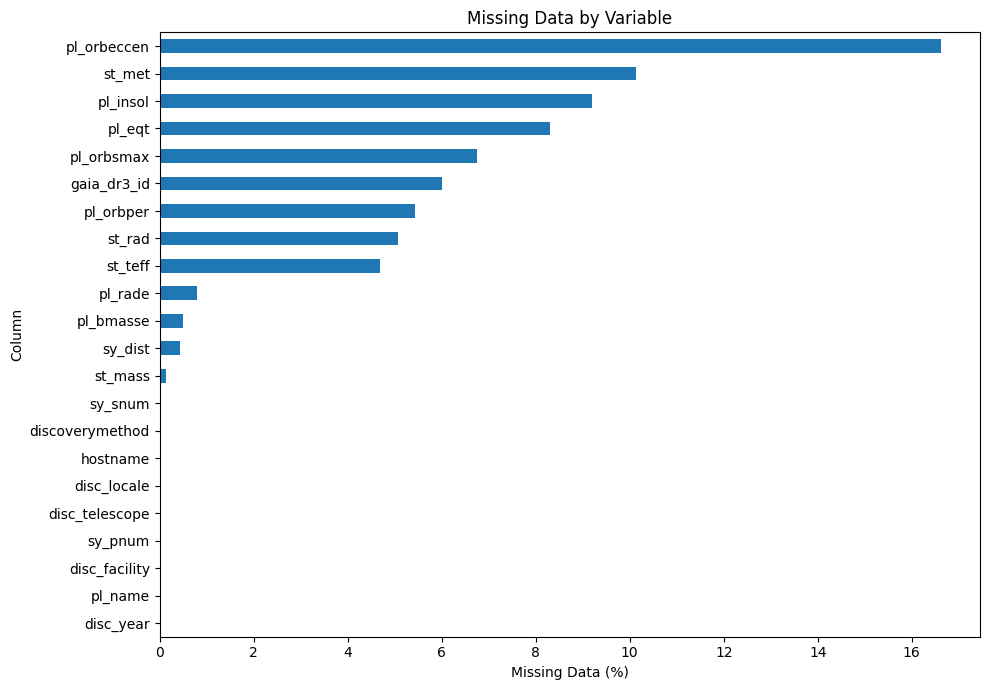

In [ ]:
plt.figure(figsize=(10, 7))

missing_report["Missing Percentage"].sort_values().plot(
    kind="barh"
)

plt.xlabel("Missing Data (%)")
plt.ylabel("Column")
plt.title("Missing Data by Variable")

plt.tight_layout()
plt.show()

In [ ]:
df.columns = (
    df.columns
    .str.strip()
    .str.lower()
)

df.columns.tolist()

['pl_name',
 'hostname',
 'gaia_dr3_id',
 'discoverymethod',
 'disc_year',
 'disc_facility',
 'disc_locale',
 'disc_telescope',
 'sy_pnum',
 'sy_snum',
 'sy_dist',
 'pl_orbper',
 'pl_orbsmax',
 'pl_rade',
 'pl_bmasse',
 'pl_eqt',
 'pl_orbeccen',
 'pl_insol',
 'st_teff',
 'st_rad',
 'st_mass',
 'st_met']

In [ ]:
numeric_columns = [
    "disc_year",
    "sy_pnum",
    "sy_snum",
    "sy_dist",
    "pl_orbper",
    "pl_orbsmax",
    "pl_rade",
    "pl_bmasse",
    "pl_eqt",
    "pl_orbeccen",
    "pl_insol",
    "st_teff",
    "st_rad",
    "st_mass",
    "st_met"
]

for column in numeric_columns:
    df[column] = pd.to_numeric(
        df[column],
        errors="coerce"
    )

In [ ]:
df[numeric_columns].dtypes

,0
disc_year,int64
sy_pnum,int64
sy_snum,int64
sy_dist,float64
pl_orbper,float64
pl_orbsmax,float64
pl_rade,float64
pl_bmasse,float64
pl_eqt,float64
pl_orbeccen,float64


In [ ]:
df["disc_year"].describe()

,disc_year
count,6336.000000
mean,2017.249369
std,5.119349
min,1992.000000
25%,2014.000000
50%,2016.000000
75%,2021.000000
max,2026.000000


In [ ]:
df["disc_year"].describe()